# Did the ad campaign lift conversion enough to justify spend?

A marketing team ran a randomized test: most users were shown an **ad**, while a holdout group saw a **public service announcement (PSA)** in the same slot instead. The business question is not only *"did the ad work?"* but *"did it work by enough to pay for the impressions?"*

**Data:** [Marketing A/B Testing (Kaggle)](https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing). One row per user: test group (`ad` / `psa`), `converted` (made a purchase), total ads seen, and the day and hour on which the user saw the most ads. There are no cost or revenue fields.

| Section | Question |
|---|---|
| 1. Data audit | Is the file clean enough to trust? |
| 2. Experiment sanity check | Is the lopsided split a problem? Were both arms delivered alike? |
| 3. Primary test | How big is the lift, and how sure are we? |
| 4. Power analysis | What is the smallest lift this design could detect? |
| 5. Segments | Where does the lift come from, and which segment results survive multiple-comparison correction? |
| 6. Business translation | Incremental purchases per 1,000 users, and where the campaign breaks even |
| 7. Recommendation | Ship, don't ship, or refine targeting? |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import HTML
from matplotlib.lines import Line2D
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import (
    confint_proportions_2indep,
    proportion_confint,
    proportions_ztest,
)

DATA_PATH = Path("data/marketing_AB.csv")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

ALPHA = 0.05  # two-sided significance level, used throughout
POWER = 0.80  # target power for the minimum-detectable-effect calculation


def table(styler, name):
    # Render a styled table with a fixed id (and no memory address in its text fallback),
    # so re-running the notebook leaves a clean git diff.
    return HTML(styler.set_uuid(name).to_html())

In [2]:
# Chart style: light surface, hairline axes, thin marks. Ad = blue and PSA = orange in every chart
# (palette slots 1-2, validated for colour-vision-deficiency separation and contrast).
SURFACE, INK, INK_2, MUTED, AXIS, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#c3c2b7", "#e1e0d9"
AD_COLOR, PSA_COLOR = "#2a78d6", "#eb6834"

sns.set_theme(style="ticks", rc={
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.titlepad": 10,
    "axes.labelsize": 9.5, "axes.labelcolor": INK_2,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "legend.frameon": False, "legend.fontsize": 9, "font.size": 9.5,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})


def save(fig, name):
    fig.savefig(FIG_DIR / name)

## 1. Data audit

Before running any statistics, check column types, missing values, duplicate rows and duplicate users. A user counted in both arms would contaminate the comparison. The first column is an unnamed row index that was saved with the CSV, so confirm that's all it is and drop it.

In [3]:
raw = pd.read_csv(DATA_PATH)
print(f"{len(raw):,} rows x {raw.shape[1]} columns")
raw.head()

588,101 rows x 7 columns


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


In [4]:
pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "nulls": raw.isna().sum(),
    "distinct values": raw.nunique(),
    "first row": raw.iloc[0],
})

,dtype,nulls,distinct values,first row
Unnamed: 0,int64,0,588101,0
user id,int64,0,588101,1069124
test group,str,0,2,ad
converted,bool,0,2,False
total ads,int64,0,807,130
most ads day,str,0,7,Monday
most ads hour,int64,0,24,20


In [5]:
# The unnamed first column must be exactly 0..n-1 (a saved row index) before it is safe to drop.
index_col = raw.columns[0]
assert (raw[index_col].to_numpy() == np.arange(len(raw))).all()
df = raw.drop(columns=index_col).rename(columns=lambda c: c.replace(" ", "_"))

DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
audit = pd.Series({
    "missing values (all columns)": df.isna().sum().sum(),
    "duplicate rows": df.duplicated().sum(),
    "duplicate user_id": df["user_id"].duplicated().sum(),
    "test_group not 'ad' or 'psa'": (~df["test_group"].isin(["ad", "psa"])).sum(),
    "most_ads_day not a weekday name": (~df["most_ads_day"].isin(DAYS)).sum(),
    "most_ads_hour outside 0-23": (~df["most_ads_hour"].between(0, 23)).sum(),
    "total_ads below 1": (df["total_ads"] < 1).sum(),
}, name="problem rows")
print(f"Dropped '{index_col}': it is the row number 0..{len(raw) - 1:,}, not data.")
print(f"Columns now: {list(df.columns)}; 'converted' dtype: {df['converted'].dtype}")
audit.to_frame()

Dropped 'Unnamed: 0': it is the row number 0..588,100, not data.
Columns now: ['user_id', 'test_group', 'converted', 'total_ads', 'most_ads_day', 'most_ads_hour']; 'converted' dtype: bool


,problem rows
missing values (all columns),0
duplicate rows,0
duplicate user_id,0
test_group not 'ad' or 'psa',0
most_ads_day not a weekday name,0
most_ads_hour outside 0-23,0
total_ads below 1,0


In [6]:
ads = df["total_ads"]
print(f"total_ads: median {ads.median():.0f}, mean {ads.mean():.1f}, 99th percentile {ads.quantile(0.99):.0f}, max {ads.max():,}")

# Derived columns used later. Exposure buckets use round-number cut points chosen for readability,
# not tuned to the results.
df["most_ads_day"] = pd.Categorical(df["most_ads_day"], categories=DAYS, ordered=True)
EXPOSURE_BINS = [0, 5, 10, 20, 50, 100, np.inf]
EXPOSURE_LABELS = ["1-5", "6-10", "11-20", "21-50", "51-100", "101+"]
df["exposure_bucket"] = pd.cut(df["total_ads"], bins=EXPOSURE_BINS, labels=EXPOSURE_LABELS)
is_ad = df["test_group"].eq("ad")

table(df["exposure_bucket"].value_counts(sort=False).rename("users").to_frame().T.style.format("{:,}"), "exposure_counts")

total_ads: median 13, mean 24.8, 99th percentile 202, max 2,065


exposure_bucket,1-5,6-10,11-20,21-50,51-100,101+
users,"177,823","82,952","127,484","130,776","46,002","23,064"


**Audit result:** the file is clean. There are no missing values and no duplicate rows, and every `user_id` appears exactly once, so each user sits in one arm only. All values are in range. `total_ads` is heavily right-skewed (median 13, max 2,065), so the segment cuts below use exposure *buckets* rather than averages.

## 2. Experiment sanity check

The split is heavily imbalanced: 564,577 users saw the ad and only 23,524 the PSA, a 96/4 split. That is normal for an ad holdout, because the control is kept small so most of the audience still sees the ad. Two questions matter more than the imbalance itself:

1. **Does the observed split match the planned split?** A *sample-ratio mismatch* (SRM) is the classic symptom of broken assignment or lost logging, and it invalidates a test.
2. **Were the two arms delivered alike** apart from the creative?

In [7]:
arms = (df.groupby("test_group")["converted"]
          .agg(users="size", conversions="sum")
          .assign(share_of_users=lambda t: t["users"] / t["users"].sum(),
                  conversion_rate=lambda t: t["conversions"] / t["users"]))
table(arms.style.format({"users": "{:,}", "conversions": "{:,}", "share_of_users": "{:.4%}", "conversion_rate": "{:.2%}"}), "arms")

,users,conversions,share_of_users,conversion_rate
test_group,,,,
ad,"564,577","14,423",96.0000%,2.55%
psa,"23,524",420,4.0000%,1.79%


### 2a. Sample-ratio check

The dataset doesn't document the planned allocation. The observed PSA share is 4.0000%, a round number that points to a deliberate 96/4 split, so that is the plan tested here with a chi-square goodness-of-fit test. The usual SRM alarm threshold is p < 0.001.

In [8]:
PLANNED_SPLIT = {"ad": 0.96, "psa": 0.04}  # inferred from the round 4.0000% PSA share; not documented in the dataset
n_total = int(arms["users"].sum())
observed = arms["users"].to_numpy()
expected = n_total * np.array([PLANNED_SPLIT[g] for g in arms.index])
srm_chi2, srm_p = stats.chisquare(observed, expected)
coin_flip_sd = np.sqrt(n_total * PLANNED_SPLIT["psa"] * PLANNED_SPLIT["ad"])

print(f"Observed PSA share: {arms.loc['psa', 'share_of_users']:.4%} (planned {PLANNED_SPLIT['psa']:.4%})")
print(f"PSA users: observed {observed[1]:,}, expected {expected[1]:,.2f}, gap {observed[1] - expected[1]:+.2f} users")
print(f"SRM chi-square = {srm_chi2:.1e}, p = {srm_p:.4f} -> {'SRM ALERT' if srm_p < 0.001 else 'no sample-ratio mismatch'}")
print(f"For scale: independent 96/4 coin flips would scatter the PSA count by about +/-{coin_flip_sd:.0f} users (1 SD)")

Observed PSA share: 4.0000% (planned 4.0000%)
PSA users: observed 23,524, expected 23,524.04, gap -0.04 users
SRM chi-square = 7.1e-08, p = 0.9998 -> no sample-ratio mismatch
For scale: independent 96/4 coin flips would scatter the PSA count by about +/-150 users (1 SD)


There is no mismatch. Two caveats:

- The 96/4 plan is inferred from the data, so this check can only catch gross problems. With the real allocation config you would test against that instead.
- The fit is *closer* than per-user coin flips usually produce: the PSA count is 0.04 users from plan, while coin-flip assignment would scatter it by about ±150. That is the signature of a fixed-size random holdout, where a set number of users is drawn at random. This is still a valid randomized design.

### 2b. Were both arms delivered alike?

`total_ads`, `most_ads_day` and `most_ads_hour` are recorded *after* assignment, so they describe delivery rather than who was assigned. If assignment and delivery worked, they should look similar in both arms. With 588k users even trivial gaps come out "significant", so judge **effect size**, not p-values. The measures are the standardized mean difference (SMD) for exposure, on the log scale because of the skew, and Cramér's V for day and hour. Below 0.1 is the usual "negligible" line.

In [9]:
def smd(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)


def cramers_v(table):
    chi2_stat = stats.chi2_contingency(table)[0]
    return np.sqrt(chi2_stat / (table.to_numpy().sum() * (min(table.shape) - 1)))


log_ads = np.log(df["total_ads"])
balance = pd.DataFrame([
    {"variable": "total_ads (log scale)", "effect size": "SMD",
     "value": smd(log_ads[is_ad], log_ads[~is_ad]),
     "p-value": stats.mannwhitneyu(df.loc[is_ad, "total_ads"], df.loc[~is_ad, "total_ads"]).pvalue},
    *[{"variable": col, "effect size": "Cramér's V",
       "value": cramers_v(pd.crosstab(df[col], df["test_group"])),
       "p-value": stats.chi2_contingency(pd.crosstab(df[col], df["test_group"]))[1]}
      for col in ["most_ads_day", "most_ads_hour"]],
]).set_index("variable")
balance["negligible (< 0.1)?"] = balance["value"].abs() < 0.1

ad_ads, psa_ads = df.loc[is_ad, "total_ads"], df.loc[~is_ad, "total_ads"]
print(f"total_ads per user, ad vs PSA: mean {ad_ads.mean():.2f} vs {psa_ads.mean():.2f}; median {ad_ads.median():.0f} vs {psa_ads.median():.0f}")
table(balance.style.format({"value": "{:.3f}", "p-value": "{:.1e}"}), "balance")

total_ads per user, ad vs PSA: mean 24.82 vs 24.76; median 13 vs 12


,effect size,value,p-value,negligible (< 0.1)?
variable,,,,
total_ads (log scale),SMD,0.042,4.7e-11,True
most_ads_day,Cramér's V,0.020,4.8e-48,True
most_ads_hour,Cramér's V,0.018,1.1e-28,True


In [10]:
# Where the day mix differs most: share of each arm's users by "most ads" day
day_mix = pd.crosstab(df["most_ads_day"], df["test_group"], normalize="columns")
day_mix["gap (ad - psa)"] = day_mix["ad"] - day_mix["psa"]
table(day_mix.style.format("{:.1%}").format("{:+.1%}", subset=["gap (ad - psa)"]), "day_mix")

test_group,ad,psa,gap (ad - psa)
most_ads_day,,,
Monday,14.8%,14.9%,-0.1%
Tuesday,13.2%,12.4%,+0.9%
Wednesday,13.7%,14.8%,-1.1%
Thursday,14.0%,16.6%,-2.6%
Friday,15.7%,16.2%,-0.4%
Saturday,14.0%,12.1%,+1.8%
Sunday,14.6%,13.0%,+1.6%


All three differences are statistically detectable, and all are negligible in size. The largest gap is in the day mix: Thursday is 14.0% of ad users but 16.6% of PSA users. The likely cause is that the ad and the PSA were paced slightly differently. Section 3 checks whether this mix difference could explain the lift.

### Why the test is still valid despite the 96/4 split

- **The imbalance is by design**, and the observed split matches the 96/4 plan (SRM p = 0.9998).
- **Unequal arm sizes don't bias the comparison.** Random assignment makes the arms comparable. Each arm's conversion rate is an unbiased estimate whatever its size, and the z-test uses each arm's own sample size.
- **What imbalance costs is precision, not validity.** The standard error is dominated by the smaller arm. Section 4 shows that the 23,524-user PSA arm still gives a minimum detectable effect well below the observed lift. Its 420 conversions are also far more than the normal approximation needs.
- **Clean units.** There is one row per user and no user is in both arms. Because the PSA runs in the same slot, the comparison isolates the ad's *content* rather than the mere presence of a banner.
- **Delivery is balanced in practice.** Exposure SMD and the day and hour Cramér's V are all far below 0.1, and Section 3 re-weights for them as a robustness check.

## 3. Primary test: did the ad lift conversion?

- **H0:** the ad and PSA arms convert at the same rate. **H1:** the rates differ. The test is two-sided, so it would also have caught an ad that *hurt* conversion.
- **Test:** two-proportion z-test (`statsmodels` `proportions_ztest`, pooled variance under H0), α = 0.05.
- **Effect sizes:** absolute lift in percentage points (pp) with a Newcombe 95% CI. This is the statsmodels default for a difference in proportions, and it stays reliable in the small segment cells of Section 5. Relative lift uses a log-ratio (Katz) 95% CI.

In [11]:
x_ad, n_ad = int(arms.loc["ad", "conversions"]), int(arms.loc["ad", "users"])
x_psa, n_psa = int(arms.loc["psa", "conversions"]), int(arms.loc["psa", "users"])
cr_ad, cr_psa = x_ad / n_ad, x_psa / n_psa

z_stat, p_value = proportions_ztest([x_ad, x_psa], [n_ad, n_psa], alternative="two-sided")
abs_lift = cr_ad - cr_psa
rel_lift = cr_ad / cr_psa - 1
abs_ci = confint_proportions_2indep(x_ad, n_ad, x_psa, n_psa, compare="diff", method="newcomb", alpha=ALPHA)
ratio_ci = confint_proportions_2indep(x_ad, n_ad, x_psa, n_psa, compare="ratio", method="log", alpha=ALPHA)
rel_ci = (ratio_ci[0] - 1, ratio_ci[1] - 1)

print(f"Ad  conversion rate: {cr_ad:.2%}  ({x_ad:,} / {n_ad:,})")
print(f"PSA conversion rate: {cr_psa:.2%}  ({x_psa:,} / {n_psa:,})")
print(f"Absolute lift: {abs_lift * 100:+.2f} pp   95% CI [{abs_ci[0] * 100:+.2f}, {abs_ci[1] * 100:+.2f}] pp")
print(f"Relative lift: {rel_lift:+.1%}    95% CI [{rel_ci[0]:+.1%}, {rel_ci[1]:+.1%}]")
print(f"Two-proportion z-test: z = {z_stat:.2f}, two-sided p = {p_value:.1e}")

Ad  conversion rate: 2.55%  (14,423 / 564,577)
PSA conversion rate: 1.79%  (420 / 23,524)
Absolute lift: +0.77 pp   95% CI [+0.59, +0.94] pp
Relative lift: +43.1%    95% CI [+30.0%, +57.5%]
Two-proportion z-test: z = 7.37, two-sided p = 1.7e-13


**Confirm with a chi-square test of independence** on the 2×2 table. Without the continuity correction it is algebraically the same test as the two-sided z-test (χ² = z²). The Yates-corrected version is slightly more conservative.

In [12]:
contingency = pd.crosstab(df["test_group"], df["converted"])
chi2, chi2_p, _, _ = stats.chi2_contingency(contingency, correction=False)
chi2_yates, chi2_yates_p, _, _ = stats.chi2_contingency(contingency, correction=True)

print(f"Chi-square (no continuity correction): χ² = {chi2:.2f}, p = {chi2_p:.1e}")
print(f"z² from the z-test:                     z² = {z_stat ** 2:.2f}  -> same test, same answer")
print(f"Chi-square (Yates-corrected):           χ² = {chi2_yates:.2f}, p = {chi2_yates_p:.1e}")
contingency

Chi-square (no continuity correction): χ² = 54.32, p = 1.7e-13
z² from the z-test:                     z² = 54.32  -> same test, same answer
Chi-square (Yates-corrected):           χ² = 54.01, p = 2.0e-13


converted,False,True
test_group,,
ad,550154,14423
psa,23104,420


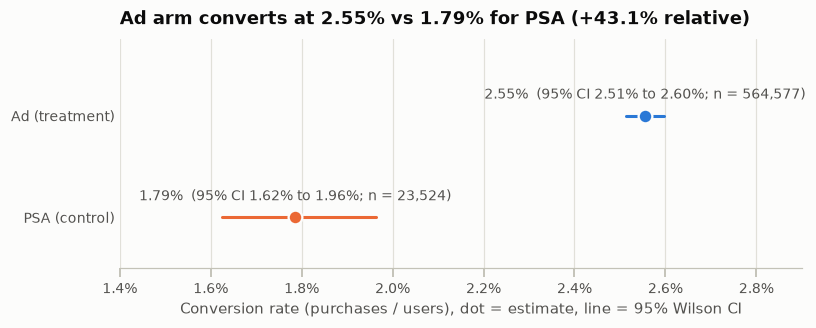

In [13]:
fig, ax = plt.subplots(figsize=(8, 2.7))
arm_rows = [("PSA (control)", x_psa, n_psa, PSA_COLOR), ("Ad (treatment)", x_ad, n_ad, AD_COLOR)]
for y, (label, x, n, color) in enumerate(arm_rows):
    lo, hi = proportion_confint(x, n, alpha=ALPHA, method="wilson")
    ax.plot([lo, hi], [y, y], color=color, lw=2, solid_capstyle="round")
    ax.plot(x / n, y, "o", ms=9, color=color, mec=SURFACE, mew=1.5)
    ax.annotate(f"{x / n:.2%}  (95% CI {lo:.2%} to {hi:.2%}; n = {n:,})", (x / n, y),
                xytext=(0, 9), textcoords="offset points", ha="center", va="bottom", color=INK_2, fontsize=9)
ax.set_yticks([0, 1], [row[0] for row in arm_rows])
ax.set_ylim(-0.5, 1.75)
ax.set_xlim(0.014, 0.029)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
ax.grid(axis="x")
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Conversion rate (purchases / users), dot = estimate, line = 95% Wilson CI")
ax.set_title(f"Ad arm converts at {cr_ad:.2%} vs {cr_psa:.2%} for PSA ({rel_lift:+.1%} relative)")
save(fig, "01_conversion_by_arm.png")
plt.show()

### Robustness: could the delivery-mix differences explain the lift?

Re-weight the PSA arm so its day, hour or exposure mix matches the ad arm's (direct standardization), then recompute the lift. If the small imbalances from Section 2 were driving the result, the re-weighted lift would move materially.

In [14]:
def reweighted_lift(by):
    # Ad rate minus the PSA rate re-weighted to the ad arm's distribution of `by`
    psa_rates = df[~is_ad].groupby(by, observed=True)["converted"].mean()
    ad_mix = df.loc[is_ad, by].value_counts(normalize=True)
    return cr_ad - (psa_rates * ad_mix).sum()


robustness = pd.Series({
    "unadjusted": abs_lift,
    "PSA re-weighted to the ad arm's day mix": reweighted_lift("most_ads_day"),
    "PSA re-weighted to the ad arm's hour mix": reweighted_lift("most_ads_hour"),
    "PSA re-weighted to the ad arm's exposure-bucket mix": reweighted_lift("exposure_bucket"),
}, name="absolute lift (pp)") * 100
max_shift = (robustness - robustness["unadjusted"]).abs().max()
print(f"Largest change from re-weighting: {max_shift:.2f} pp")
robustness.round(2).to_frame()

Largest change from re-weighting: 0.03 pp


,absolute lift (pp)
unadjusted,0.77
PSA re-weighted to the ad arm's day mix,0.78
PSA re-weighted to the ad arm's hour mix,0.78
PSA re-weighted to the ad arm's exposure-bucket mix,0.80


**Result:** the ad arm converts at 2.55% vs 1.79% for the PSA arm, a lift of **+0.77 pp (+43.1% relative)**. The 95% CI runs from +0.59 to +0.94 pp, with p = 1.7e-13. The chi-square test gives the same answer, and re-weighting for the delivery-mix differences moves the lift by at most 0.03 pp. The lift is real. Whether it is *big enough to pay for itself* is the subject of Section 6.

## 4. Power analysis: what could this test detect?

The PSA arm is only 23,524 users, so it sets the limit on precision. The **minimum detectable effect (MDE)** is the smallest true lift the test would catch 80% of the time at α = 0.05 (two-sided), given the actual arm sizes and the PSA baseline rate. `statsmodels` `NormalIndPower` solves for Cohen's *h*, an arcsine-scaled difference in proportions, which is then converted back to conversion-rate units.

In [15]:
def mde(n_control, ratio, baseline, alpha=ALPHA, power=POWER):
    # Smallest absolute lift over `baseline` detectable with n_control users and ratio = n_treatment / n_control
    h = NormalIndPower().solve_power(effect_size=None, nobs1=n_control, ratio=ratio,
                                     alpha=alpha, power=power, alternative="two-sided")
    return np.sin(np.arcsin(np.sqrt(baseline)) + float(h) / 2) ** 2 - baseline


ratio = n_ad / n_psa
mde_abs = mde(n_psa, ratio, cr_psa)
print(f"PSA baseline conversion rate {cr_psa:.2%}; allocation ad:PSA = {ratio:.1f}:1")
print(f"MDE: {mde_abs * 100:+.2f} pp absolute = {mde_abs / cr_psa:+.1%} relative")
print(f"Observed lift: {abs_lift * 100:+.2f} pp = {abs_lift / mde_abs:.1f}x the MDE")

designs = pd.DataFrame([
    (f"Actual: {n_ad:,} ad / {n_psa:,} PSA", n_psa, ratio),
    (f"Same {n_psa:,}-user PSA arm, unlimited ad users", n_psa, 1e6),
    (f"Same {n_total:,} users split 50/50", n_total / 2, 1.0),
], columns=["design", "psa_users", "ratio"]).set_index("design")
designs["MDE (pp)"] = [mde(n, r, cr_psa) * 100 for n, r in zip(designs["psa_users"], designs["ratio"])]
designs["MDE (relative)"] = designs["MDE (pp)"] / 100 / cr_psa
designs["vs actual"] = designs["MDE (pp)"] / designs["MDE (pp)"].iloc[0]
table(designs[["MDE (pp)", "MDE (relative)", "vs actual"]].style.format(
    {"MDE (pp)": "{:+.2f}", "MDE (relative)": "{:+.1%}", "vs actual": "{:.2f}x"}), "designs")

PSA baseline conversion rate 1.79%; allocation ad:PSA = 24.0:1
MDE: +0.26 pp absolute = +14.3% relative
Observed lift: +0.77 pp = 3.0x the MDE


,MDE (pp),MDE (relative),vs actual
design,,,
"Actual: 564,577 ad / 23,524 PSA",+0.26,+14.3%,1.00x
"Same 23,524-user PSA arm, unlimited ad users",+0.25,+14.0%,0.98x
"Same 588,101 users split 50/50",+0.10,+5.5%,0.38x


Full test: 23,524 PSA users -> MDE +14% relative
Median day segment: 3,490 PSA users -> MDE +39% relative
Median hour segment: 1,079 PSA users -> MDE +75% relative


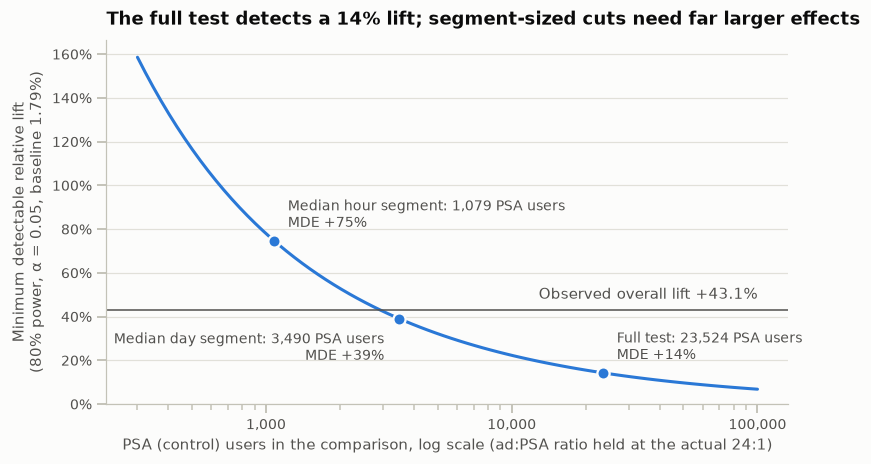

In [16]:
psa = df[~is_ad]
typical_segments = {
    "Median day segment": psa["most_ads_day"].value_counts().median(),
    "Median hour segment": psa["most_ads_hour"].value_counts().median(),
}
psa_sizes = np.geomspace(300, 100_000, 80)
mde_rel_curve = np.array([mde(n, ratio, cr_psa) for n in psa_sizes]) / cr_psa

fig, ax = plt.subplots(figsize=(8, 4.3))
ax.plot(psa_sizes, mde_rel_curve, color=AD_COLOR, lw=2, solid_capstyle="round")
ax.axhline(rel_lift, color=INK_2, lw=1)
ax.annotate(f"Observed overall lift {rel_lift:+.1%}", (psa_sizes[-1], rel_lift), xytext=(0, 5),
            textcoords="offset points", ha="right", va="bottom", color=INK_2)
label_offsets = {"Full test": (9, 6, "left", "bottom"), "Median day segment": (-10, -8, "right", "top"),
                 "Median hour segment": (9, 6, "left", "bottom")}
for label, n in {"Full test": n_psa, **typical_segments}.items():
    m = mde(n, ratio, cr_psa) / cr_psa
    print(f"{label}: {n:,.0f} PSA users -> MDE {m:+.0%} relative")
    dx, dy, ha, va = label_offsets[label]
    ax.plot(n, m, "o", ms=8, color=AD_COLOR, mec=SURFACE, mew=1.5, zorder=3)
    ax.annotate(f"{label}: {n:,.0f} PSA users\nMDE {m:+.0%}", (n, m), xytext=(dx, dy),
                textcoords="offset points", ha=ha, va=va, color=INK_2, fontsize=9)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, mde_rel_curve.max() * 1.05)
ax.grid(axis="y")
ax.set_xlabel("PSA (control) users in the comparison, log scale (ad:PSA ratio held at the actual 24:1)")
ax.set_ylabel(f"Minimum detectable relative lift\n(80% power, α = 0.05, baseline {cr_psa:.2%})")
ax.set_title(f"The full test detects a {mde_abs / cr_psa:.0%} lift; segment-sized cuts need far larger effects")
save(fig, "02_mde_by_control_size.png")
plt.show()

**Result:** at full size the test can detect a lift of about +0.26 pp (+14.3% relative). The observed +0.77 pp is 3.0x that, so the test was well powered for the effect it found. Two design lessons:

- **The PSA arm is the bottleneck.** Unlimited ad users would barely shrink the MDE (0.98x). A 50/50 split of the same users would detect effects 0.38x the size, but only by withholding the ad from half the audience during the test. The 96/4 design deliberately trades precision for reach.
- **Segment cuts are underpowered.** A median day segment has 3,490 PSA users and a median hour segment 1,079, so their MDEs are far larger (chart). In Section 5, "not significant" in a segment mostly means "not measurable", not "no effect".